In [1]:
print('h')

h


In [2]:
%pip install evaluate
%pip install contractions

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 2.9 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 345.1/345.1 kB 7.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.9/114.9 kB 9.7 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


In [3]:
!rm -rf /kaggle/working/*

# Dataset Loading and Train-Test-Validation Splitting

## Loading

In [4]:
from datasets import load_dataset, load_from_disk, Dataset, DatasetDict

aug_file_path = "/kaggle/input/datasets/shadmanshafeen141/bpd-qna-classification-dataset-augmented/augmented_dataset"
# file_path = "/kaggle/input/datasets/shadmanshafeen141/bpd-question-and-answer-classification-dataset/BPDQAC Dataset.csv"  # Baseline raw dataset disabled
# dataset = load_dataset("csv" , data_files=file_path)  # Disabled: baseline path not used
augmented_dataset = load_from_disk(aug_file_path)

# Keep a compatibility variable for downstream exploratory cells
dataset = augmented_dataset["train"]

print("Augmented Dataset:", augmented_dataset)
print("Working Dataset (train split):", dataset)

Augmented Dataset: DatasetDict({
    train: Dataset({
        features: ['id', 'participant_id', 'question_id', 'question', 'answer', 'label', 'Criteria B', 'Criteria C', 'Criteria D', 'Criteria E', 'Criteria F'],
        num_rows: 5238
    })
    test: Dataset({
        features: ['id', 'participant_id', 'question_id', 'question', 'answer', 'label', 'Criteria B', 'Criteria C', 'Criteria D', 'Criteria E', 'Criteria F'],
        num_rows: 333
    })
    validation: Dataset({
        features: ['id', 'participant_id', 'question_id', 'question', 'answer', 'label', 'Criteria B', 'Criteria C', 'Criteria D', 'Criteria E', 'Criteria F'],
        num_rows: 333
    })
})
Working Dataset (train split): Dataset({
    features: ['id', 'participant_id', 'question_id', 'question', 'answer', 'label', 'Criteria B', 'Criteria C', 'Criteria D', 'Criteria E', 'Criteria F'],
    num_rows: 5238
})


## Solving Contractions

In [5]:
import pandas as pd
import numpy as np
import re
import contractions  # Make sure to install: pip install contractions

class TextNormalizer:
    def __init__(self):
        # Initialize text normalization dictionary
        self.slang_dict = {
            'imo': 'in my opinion',
            'imho': 'in my humble opinion',
            'tbh': 'to be honest',
            'afaik': 'as far as i know',
            'idk': "i don't know",
            'smh': 'shaking my head',
            'btw': 'by the way',
            'asap': 'as soon as possible',
            'fyi': 'for your information',
            'np': 'no problem',
            'thx': 'thanks',
            'pls': 'please',
            'u': 'you',
            'r': 'are',
            'ur': 'your',
            'n': 'and',
            'b/c': 'because',
            'cz' : 'because',
            'bcz' : 'because',
            'ofc' : 'ofcourse',
            'govt': 'government',
            'dept': 'department',
            'est': 'established',
            'approx': 'approximately',
            'min': 'minimum',
            'max': 'maximum',
            "n't": 'not',
            "nt" : 'not',
            "gn" : 'good night',
            "f9" : 'fine',
            'bpd': 'borderline personality disorder',
            'dbt': 'dialectical behavior therapy',
            'fp': 'favorite person',
            'si': 'suicidal ideation',
            'sh': 'self harm',
            "its" : 'it is',
            "people's" : 'people',
            "sha'n't": "shall not",
            "shan't've": "shall not have",
            "she'd": "she had / she would",
            "she'd've": "she would have",
            "she'll": "she shall / she will",
            "she'll've": "she shall have / she will have",
            "she's": "she has / she is",
            "should've": "should have",
            "shouldn't": "should not",
            "shouldn't've": "should not have",
            "so've": "so have",
            "so's": "so as / so is",
            "that'd": "that would / that had",
            "that'd've": "that would have",
            "that's": "that has / that is",
            "there'd": "there had / there would",
            "there'd've": "there would have",
            "there's": "there has / there is",
            "they'd": "they had / they would",
            "they'd've": "they would have",
            "they'll": "they shall / they will",
            "they'll've": "they shall have / they will have",
            "they're": "they are",
            "they've": "they have",
            "to've": "to have",
            "wasn't": "was not",
            "we'd": "we had / we would",
            "we'd've": "we would have",
            "we'll": "we will",
            "we'll've": "we will have",
            "we're": "we are",
            "we've": "we have",
            "weren't": "were not",
            "what'll": "what shall / what will",
            "what'll've": "what shall have / what will have",
            "what're": "what are",
            "what's": "what has / what is",
            "what've": "what have",
            "when's": "when has / when is",
            "when've": "when have",
            "where'd": "where did",
            "where's": "where has / where is",
            "where've": "where have",
            "who'll": "who shall / who will",
            "who'll've": "who shall have / who will have",
            "who's": "who has / who is",
            "who've": "who have",
            "why's": "why has / why is",
            "why've": "why have",
            "will've": "will have",
            "won't": "will not",
            "won't've": "will not have",
            "would've": "would have",
            "wouldn't": "would not",
            "wouldn't've": "would not have",
            "y'all": "you all",
            "y'all'd": "you all would",
            "y'all'd've": "you all would have",
            "y'all're": "you all are",
            "y'all've": "you all have",
            "you'd": "you had / you would",
            "you'd've": "you would have",
            "you'll": "you shall / you will",
            "you'll've": "you shall have / you will have",
            "you're": "you are",
            "you've": "you have"
}

    def clean_text(self, text):
        """Basic text cleaning"""
        text = str(text).lower().strip()
        # Remove special characters (keep basic punctuation)
        text = re.sub(r"[^a-zA-Z0-9\s.,!?']", "", text)
        return text

    def expand_slang(self, text):
        """Replace slang terms using dictionary"""
        words = text.split()
        expanded_words = [self.slang_dict.get(word, word) for word in words]
        return ' '.join(expanded_words)

    def normalize_text(self, text):
        """Full text normalization pipeline"""
        if not isinstance(text, str) or not text.strip():
            return text
            
        # Clean text first
        text = self.clean_text(text)
        # Fix contractions
        text = contractions.fix(text)
        # Expand slang
        text = self.expand_slang(text)
        return text

# Convert to pandas DataFrame for easier processing
df = dataset.to_pandas()
aug_df_train = augmented_dataset['train'].to_pandas()
aug_df_test = augmented_dataset['test'].to_pandas()
aug_df_validation = augmented_dataset['validation'].to_pandas()

# Initialize normalizer
normalizer = TextNormalizer()

# Apply normalization to text columns
text_columns = ['question', 'answer']
for col in text_columns:
    df[col] = df[col].apply(normalizer.normalize_text)
    aug_df_train[col] = aug_df_train[col].apply(normalizer.normalize_text)
    aug_df_test[col] = aug_df_test[col].apply(normalizer.normalize_text)
    aug_df_validation[col] = aug_df_validation[col].apply(normalizer.normalize_text)
    
clean_dataset = Dataset.from_pandas(df, preserve_index=False)

aug_clean_dataset_train = Dataset.from_pandas(aug_df_train, preserve_index=False)
aug_clean_dataset_test = Dataset.from_pandas(aug_df_test, preserve_index=False)
aug_clean_dataset_validation =  Dataset.from_pandas(aug_df_validation, preserve_index=False)
aug_clean_dataset = DatasetDict({
    "train":aug_clean_dataset_train,
    "test":aug_clean_dataset_test,
    "validation":aug_clean_dataset_validation
})
dataset = clean_dataset
augmented_dataset = aug_clean_dataset

## Question-Wise Stratified Splitting

In [6]:
# Baseline question-wise stratified split is disabled for augmented-only workflow.
# from collections import Counter
# from datasets import concatenate_datasets, DatasetDict
# qid_split_ds = {}
# ds = dataset.class_encode_column("label")
# for qid in range(1, 10):
#     split_ds = ds.filter(lambda row, q=qid: row["question_id"] == q)
#     qid_split_ds[qid] = split_ds
# question_split_dataset = {}
# train_splits = dataset.select([])
# test_splits = dataset.select([])
# validation_splits = dataset.select([])
# for i in range(1,10):
#     split1 = qid_split_ds[i].train_test_split(test_size=0.1 , seed=42, stratify_by_column="label")
#     split2 = split1["train"].train_test_split(test_size=0.1111 , seed=42, stratify_by_column="label")
#     train_splits = concatenate_datasets([split2['train'] , train_splits])
#     test_splits = concatenate_datasets([split2['test'] , test_splits])
#     validation_splits = concatenate_datasets([split1['test'] , validation_splits])
# question_split_dataset = DatasetDict({
#     'train' : train_splits,
#     'test' : test_splits,
#     'validation' : validation_splits
# })
# print(f"\nTrain set: {question_split_dataset['train'].num_rows} rows")
# print(f"Class Distribution: {Counter(question_split_dataset['train']['label'])}")
# print(f"\nTest set: {question_split_dataset['test'].num_rows} rows")
# print(f"Class Distribution: {Counter(question_split_dataset['test']['label'])}")
# print(f"\nValidation set: {question_split_dataset['validation'].num_rows} rows")
# print(f"Class Distribution: {Counter(question_split_dataset['validation']['label'])}")
# print("\n",Counter(question_split_dataset['train']['question_id']))

# For augmented-only workflow, use augmented split directly.
question_split_dataset = augmented_dataset
print("Baseline split disabled. Using augmented dataset splits directly.")

Baseline split disabled. Using augmented dataset splits directly.


## Data Visualization

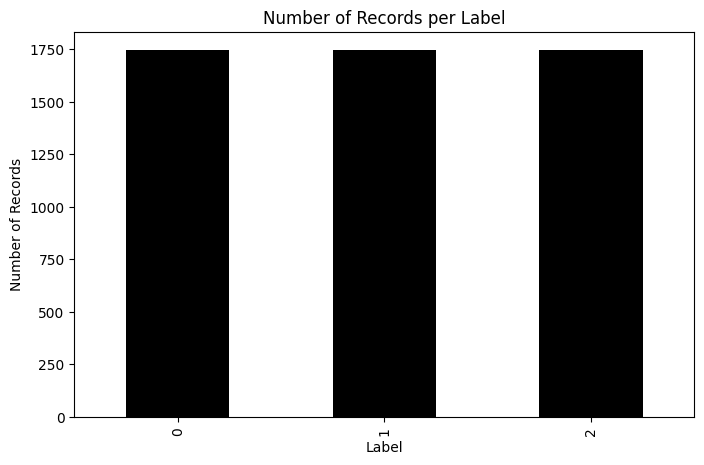

In [7]:
import matplotlib.pyplot as plt

df = dataset.to_pandas()

# Use pandas value_counts to count the labels
label_counts = df['label'].value_counts().sort_index()

label_counts.plot(kind='bar', figsize=(8, 5), color='black')
plt.xlabel('Label')
plt.ylabel('Number of Records')
plt.title('Number of Records per Label')
plt.show()

## Class Weights for Weighted Cross-Entropy Loss
###  Weight of Class i = sqrt (Total Number of Examples)/(Number of Classes x Examples in Class i)

In [8]:
# Weighted Cross-Entropy class weights are disabled per experiment scope.
# from sklearn.utils.class_weight import compute_class_weight
# import numpy as np
# import torch
# classes=np.unique(question_split_dataset['train']['label'])
# class_weights = compute_class_weight(class_weight='balanced', classes=np.unique(question_split_dataset['train']['label']), y=question_split_dataset['train']['label'])
# class_weights = torch.tensor(class_weights)
# class_weights = torch.sqrt(class_weights)
# class_weights = class_weights / class_weights.sum() * len(class_weights)
# class_weights = class_weights.to(device='cuda', dtype=torch.float32)
# print (f"Class Weights: {class_weights}")
print("Skipped: class-weight computation disabled (no weighted-loss runs).")

Skipped: class-weight computation disabled (no weighted-loss runs).


## Checking for Null Values

In [9]:
df = dataset.to_pandas()

# 2. Identify rows with at least one null
mask = df.isnull().any(axis=1)

# 3. Extract and print those rows
null_df = df[mask]
print(null_df)

Empty DataFrame
Columns: [id, participant_id, question_id, question, answer, label, Criteria B, Criteria C, Criteria D, Criteria E, Criteria F]
Index: []


# Tokenization

## Tokenization Function

In [10]:
# tokenizer also passed to ensure used tokenizer is of same checkpoint as the model
# Dynamic Padding. Hence, dp
def tokenize(example , tokenizer):
    return tokenizer(example["question"], example["answer"], truncation=True)

## Tokenization

In [11]:
from transformers import AutoTokenizer

### Electra

In [12]:
electra_checkpoint = 'google/electra-base-discriminator'
electra_tokenizer = AutoTokenizer.from_pretrained(electra_checkpoint)
# tokenized_dataset_dp_electra = question_split_dataset.map(tokenize, batched=True , fn_kwargs= {'tokenizer' : electra_tokenizer})  # Raw baseline disabled
augmented_tokenized_dataset_dp_electra = augmented_dataset.map(tokenize, batched=True , fn_kwargs= {'tokenizer' : electra_tokenizer})

config.json:   0%|          | 0.00/666 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Map:   0%|          | 0/5238 [00:00<?, ? examples/s]

Map:   0%|          | 0/333 [00:00<?, ? examples/s]

Map:   0%|          | 0/333 [00:00<?, ? examples/s]

### BERT

In [13]:
bert_checkpoint = "bert-base-uncased"
bert_tokenizer = AutoTokenizer.from_pretrained(bert_checkpoint)
# tokenized_dataset_dp_bert = question_split_dataset.map(tokenize , batched = True , fn_kwargs = {'tokenizer' : bert_tokenizer})  # Raw baseline disabled
augmented_tokenized_dataset_dp_bert = augmented_dataset.map(tokenize , batched = True , fn_kwargs = {'tokenizer' : bert_tokenizer})

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Map:   0%|          | 0/5238 [00:00<?, ? examples/s]

Map:   0%|          | 0/333 [00:00<?, ? examples/s]

Map:   0%|          | 0/333 [00:00<?, ? examples/s]

###  DistilBERT

In [14]:
distilbert_checkpoint = "distilbert/distilbert-base-uncased"
distilbert_tokenizer = AutoTokenizer.from_pretrained(distilbert_checkpoint)
# tokenized_dataset_dp_distilbert = question_split_dataset.map(tokenize, batched=True , fn_kwargs= {'tokenizer' : distilbert_tokenizer})  # Raw baseline disabled
augmented_tokenized_dataset_dp_distilbert = augmented_dataset.map(tokenize, batched=True , fn_kwargs= {'tokenizer' : distilbert_tokenizer})

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Map:   0%|          | 0/5238 [00:00<?, ? examples/s]

Map:   0%|          | 0/333 [00:00<?, ? examples/s]

Map:   0%|          | 0/333 [00:00<?, ? examples/s]

### RoBERTa

In [15]:
roberta_checkpoint = "FacebookAI/roberta-base"
roberta_tokenizer = AutoTokenizer.from_pretrained(roberta_checkpoint)
# tokenized_dataset_dp_roberta = question_split_dataset.map(tokenize, batched=True , fn_kwargs= {'tokenizer' : roberta_tokenizer})  # Raw baseline disabled
augmented_tokenized_dataset_dp_roberta = augmented_dataset.map(tokenize, batched=True , fn_kwargs= {'tokenizer' : roberta_tokenizer})

config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Map:   0%|          | 0/5238 [00:00<?, ? examples/s]

Map:   0%|          | 0/333 [00:00<?, ? examples/s]

Map:   0%|          | 0/333 [00:00<?, ? examples/s]

### PsychBERT

In [16]:
# PsychBERT tokenization is disabled entirely per experiment scope.
# psychbert_checkpoint = "mnaylor/psychbert-cased"
# psychbert_tokenizer = AutoTokenizer.from_pretrained(psychbert_checkpoint)
# tokenized_dataset_dp_psychbert = question_split_dataset.map(tokenize, batched=True , fn_kwargs= {'tokenizer' : psychbert_tokenizer})
# augmented_tokenized_dataset_dp_psychbert = augmented_dataset.map(tokenize, batched=True , fn_kwargs= {'tokenizer' : psychbert_tokenizer})
print("Skipped: PsychBERT section disabled.")

Skipped: PsychBERT section disabled.


### XLNet

In [17]:
xlnet_checkpoint = "xlnet/xlnet-base-cased"
xlnet_tokenizer = AutoTokenizer.from_pretrained(xlnet_checkpoint)
# tokenized_dataset_dp_xlnet = question_split_dataset.map(tokenize, batched=True , fn_kwargs= {'tokenizer' : xlnet_tokenizer})  # Raw baseline disabled
augmented_tokenized_dataset_dp_xlnet = augmented_dataset.map(tokenize, batched=True , fn_kwargs= {'tokenizer' : xlnet_tokenizer})

config.json:   0%|          | 0.00/760 [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/798k [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Map:   0%|          | 0/5238 [00:00<?, ? examples/s]

Map:   0%|          | 0/333 [00:00<?, ? examples/s]

Map:   0%|          | 0/333 [00:00<?, ? examples/s]

### DeBERTa

In [18]:
deberta_checkpoint = "microsoft/deberta-v3-base"
deberta_tokenizer = AutoTokenizer.from_pretrained(deberta_checkpoint, use_fast=False)
# tokenized_dataset_dp_deberta = question_split_dataset.map(tokenize, batched=True , fn_kwargs= {'tokenizer' : deberta_tokenizer})  # Raw baseline disabled
augmented_tokenized_dataset_dp_deberta = augmented_dataset.map(tokenize, batched=True , fn_kwargs= {'tokenizer' : deberta_tokenizer})


config.json:   0%|          | 0.00/579 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

spm.model:   0%|          | 0.00/2.46M [00:00<?, ?B/s]

Map:   0%|          | 0/5238 [00:00<?, ? examples/s]

Map:   0%|          | 0/333 [00:00<?, ? examples/s]

Map:   0%|          | 0/333 [00:00<?, ? examples/s]

### ModernBERT


In [19]:
modernbert_checkpoint = "answerdotai/ModernBERT-base"
try:
    modernbert_tokenizer = AutoTokenizer.from_pretrained(modernbert_checkpoint)
except Exception as ex:
    raise RuntimeError(
        "ModernBERT could not be loaded in this environment. If your Transformers build is too old, upgrade it before running this cell."
    ) from ex
# tokenized_dataset_dp_modernbert = question_split_dataset.map(tokenize, batched=True, fn_kwargs={'tokenizer': modernbert_tokenizer})  # Raw baseline disabled
augmented_tokenized_dataset_dp_modernbert = augmented_dataset.map(tokenize, batched=True, fn_kwargs={'tokenizer': modernbert_tokenizer})


config.json: 0.00B [00:00, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/694 [00:00<?, ?B/s]

Map:   0%|          | 0/5238 [00:00<?, ? examples/s]

Map:   0%|          | 0/333 [00:00<?, ? examples/s]

Map:   0%|          | 0/333 [00:00<?, ? examples/s]

### T5

In [20]:
t5_checkpoint = "google-t5/t5-small"

from transformers import T5Tokenizer
t5_tokenizer = T5Tokenizer.from_pretrained(t5_checkpoint)

def t5_preprocess(example):
    inputs = [
        f"trinary classification: {question} </s> {answer}"
        for question, answer in zip(example["question"], example["answer"])
    ]
    model_inputs = t5_tokenizer(
        inputs,
        max_length=512,
        truncation=True,
    )
    return model_inputs

# tokenized_dataset_dp_t5 = question_split_dataset.map(t5_preprocess, batched=True)  # Raw baseline disabled
augmented_tokenized_dataset_dp_t5 = augmented_dataset.map(t5_preprocess, batched=True)

tokenizer_config.json: 0.00B [00:00, ?B/s]

spiece.model:   0%|          | 0.00/792k [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Map:   0%|          | 0/5238 [00:00<?, ? examples/s]

Map:   0%|          | 0/333 [00:00<?, ? examples/s]

Map:   0%|          | 0/333 [00:00<?, ? examples/s]

# Evaluate Function

In [21]:
import numpy as np
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

def compute_metrics(evaluation_predictions):
    logits, actual_labels = evaluation_predictions
    predicted_labels = np.argmax(logits, axis=-1)

    accuracy = accuracy_score(actual_labels, predicted_labels)
    precision, recall, f1, _ = precision_recall_fscore_support(
        actual_labels, predicted_labels, average='weighted', zero_division=0
    )

    return {
        "accuracy": accuracy,
        "f1": f1,
        "precision": precision,
        "recall": recall
    }

# Training

In [22]:
import gc
import json
import inspect
from contextlib import contextmanager, nullcontext
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from transformers import (
    AutoModelForSequenceClassification,
    AutoTokenizer,
    DataCollatorWithPadding,
    T5ForSequenceClassification,
    T5Tokenizer,
    Trainer,
    TrainingArguments,
)

MODEL_ARTIFACT_ROOT = Path("./model_artifacts")
MODEL_ARTIFACT_ROOT.mkdir(parents=True, exist_ok=True)

MODEL_RUNTIME_SPECS = {
    "ELECTRA": {
        "trainer_name": "electra_aug_trainer",
        "token_ds_name": "augmented_tokenized_dataset_dp_electra",
        "tokenizer_name": "electra_tokenizer",
        "artifact_dir": "electra_augmented",
        "model_loader": "auto",
    },
    "BERT": {
        "trainer_name": "bert_aug_trainer",
        "token_ds_name": "augmented_tokenized_dataset_dp_bert",
        "tokenizer_name": "bert_tokenizer",
        "artifact_dir": "bert_augmented",
        "model_loader": "auto",
    },
    "DistilBERT": {
        "trainer_name": "distilbert_aug_trainer",
        "token_ds_name": "augmented_tokenized_dataset_dp_distilbert",
        "tokenizer_name": "distilbert_tokenizer",
        "artifact_dir": "distilbert_augmented",
        "model_loader": "auto",
    },
    "RoBERTa": {
        "trainer_name": "roberta_aug_trainer",
        "token_ds_name": "augmented_tokenized_dataset_dp_roberta",
        "tokenizer_name": "roberta_tokenizer",
        "artifact_dir": "roberta_augmented",
        "model_loader": "auto",
    },
    "XLNet": {
        "trainer_name": "xlnet_aug_trainer",
        "token_ds_name": "augmented_tokenized_dataset_dp_xlnet",
        "tokenizer_name": "xlnet_tokenizer",
        "artifact_dir": "xlnet_augmented",
        "model_loader": "auto",
    },
    "DeBERTa": {
        "trainer_name": "deberta_aug_trainer",
        "token_ds_name": "augmented_tokenized_dataset_dp_deberta",
        "tokenizer_name": "deberta_tokenizer",
        "artifact_dir": "deberta_augmented",
        "model_loader": "auto",
    },
    "ModernBERT": {
        "trainer_name": "modernbert_aug_trainer",
        "token_ds_name": "augmented_tokenized_dataset_dp_modernbert",
        "tokenizer_name": "modernbert_tokenizer",
        "artifact_dir": "modernbert_augmented",
        "model_loader": "auto",
    },
    "T5": {
        "trainer_name": "t5_aug_trainer",
        "token_ds_name": "augmented_tokenized_dataset_dp_t5",
        "tokenizer_name": "t5_tokenizer",
        "artifact_dir": "t5_augmented",
        "model_loader": "t5",
    },
}

def get_model_artifact_dir(model_name):
    model_dir = MODEL_ARTIFACT_ROOT / MODEL_RUNTIME_SPECS[model_name]["artifact_dir"]
    model_dir.mkdir(parents=True, exist_ok=True)
    return model_dir

def _extract_pred_labels(pred_output):
    preds = pred_output.predictions
    if isinstance(preds, tuple):
        preds = preds[0]
    preds = np.asarray(preds)
    if preds.ndim == 1:
        return preds.astype(int)
    return np.argmax(preds, axis=-1)

def _resolve_saved_model_dir(model_name):
    artifact_dir = get_model_artifact_dir(model_name)
    if (artifact_dir / "config.json").exists():
        return artifact_dir

    checkpoint_dirs = sorted(
        [path for path in artifact_dir.glob("checkpoint-*") if path.is_dir()],
        key=lambda path: int(path.name.split("-")[-1]),
    )
    if checkpoint_dirs:
        return checkpoint_dirs[-1]
    return None

def _load_saved_components(model_name):
    spec = MODEL_RUNTIME_SPECS[model_name]
    saved_model_dir = _resolve_saved_model_dir(model_name)
    if saved_model_dir is None:
        raise FileNotFoundError(
            f"No saved checkpoint found for {model_name} in {get_model_artifact_dir(model_name)}"
        )

    if spec["model_loader"] == "t5":
        tokenizer = globals().get(spec["tokenizer_name"]) or T5Tokenizer.from_pretrained(saved_model_dir)
        model = T5ForSequenceClassification.from_pretrained(saved_model_dir)
    else:
        tokenizer = globals().get(spec["tokenizer_name"])
        if tokenizer is None:
            tokenizer = AutoTokenizer.from_pretrained(
                saved_model_dir,
                use_fast=(model_name != "DeBERTa"),
            )
        model = AutoModelForSequenceClassification.from_pretrained(saved_model_dir)
        if model_name == "XLNet":
            tokenizer.padding_side = "left"
            model.config.pad_token_id = tokenizer.pad_token_id

    return model, tokenizer, saved_model_dir

@contextmanager
def force_single_gpu_visibility(enabled=False):
    if (not enabled) or (not torch.cuda.is_available()):
        yield
        return

    original_device_count = torch.cuda.device_count
    torch.cuda.device_count = lambda: 1
    try:
        yield
    finally:
        torch.cuda.device_count = original_device_count

def _mixed_precision_training_kwargs():
    if not torch.cuda.is_available():
        return {"fp16": False, "bf16": False}
    if hasattr(torch.cuda, "is_bf16_supported") and torch.cuda.is_bf16_supported():
        return {"fp16": False, "bf16": True}
    return {"fp16": True, "bf16": False}

TRAINING_PRECISION_KWARGS = _mixed_precision_training_kwargs()
_ORIGINAL_TORCH_CUDA_DEVICE_COUNT = torch.cuda.device_count

def configure_trainer_runtime_for_notebook(precision_kwargs=None):
    precision_kwargs = precision_kwargs or TRAINING_PRECISION_KWARGS
    enable_single_gpu = (
        torch.cuda.is_available()
        and _ORIGINAL_TORCH_CUDA_DEVICE_COUNT() > 1
        and (precision_kwargs.get("fp16") or precision_kwargs.get("bf16"))
    )
    torch.cuda.device_count = (
        (lambda: 1) if enable_single_gpu else _ORIGINAL_TORCH_CUDA_DEVICE_COUNT
    )
    return enable_single_gpu

SINGLE_GPU_TRAINER_RUNTIME = configure_trainer_runtime_for_notebook()

def training_precision_mode_label(precision_kwargs=None):
    precision_kwargs = precision_kwargs or TRAINING_PRECISION_KWARGS
    if precision_kwargs.get("bf16"):
        return "bf16"
    if precision_kwargs.get("fp16"):
        return "fp16"
    return "fp32"

if SINGLE_GPU_TRAINER_RUNTIME:
    print(
        f"Notebook trainer stability mode enabled: using {training_precision_mode_label()} on a single visible GPU."
    )

def _trainer_tokenizer_arg_name():
    trainer_signature = inspect.signature(Trainer.__init__)
    if "processing_class" in trainer_signature.parameters:
        return "processing_class"
    if "tokenizer" in trainer_signature.parameters:
        return "tokenizer"
    return None

def predict_augmented_model(model_name):
    spec = MODEL_RUNTIME_SPECS[model_name]
    if spec["token_ds_name"] not in globals():
        raise KeyError(
            f"{spec['token_ds_name']} is not available. Run the tokenization cell for {model_name} first."
        )

    tokenized_ds = globals()[spec["token_ds_name"]]
    trainer_name = spec["trainer_name"]

    if trainer_name in globals():
        pred_output = globals()[trainer_name].predict(tokenized_ds["test"])
        source = "in-memory trainer"
        if SINGLE_GPU_TRAINER_RUNTIME:
            source += " (single-GPU stability mode)"
        return _extract_pred_labels(pred_output), source

    prediction_context = force_single_gpu_visibility(SINGLE_GPU_TRAINER_RUNTIME)
    with prediction_context:
        model, tokenizer, saved_model_dir = _load_saved_components(model_name)
        data_collator = DataCollatorWithPadding(tokenizer=tokenizer)
        eval_args = TrainingArguments(
            output_dir=str(get_model_artifact_dir(model_name) / "_eval_runtime"),
            per_device_eval_batch_size=2 if model_name == "XLNet" else 8,
            report_to=[],
        )
        eval_trainer_kwargs = {
            "model": model,
            "args": eval_args,
            "data_collator": data_collator,
        }
        trainer_tokenizer_arg = _trainer_tokenizer_arg_name()
        if trainer_tokenizer_arg is not None:
            eval_trainer_kwargs[trainer_tokenizer_arg] = tokenizer
        eval_trainer = Trainer(**eval_trainer_kwargs)

        try:
            pred_output = eval_trainer.predict(tokenized_ds["test"])
        finally:
            del eval_trainer
            del model
            gc.collect()
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

    return _extract_pred_labels(pred_output), f"saved artifact: {saved_model_dir}"

def evaluate_augmented_model(model_name):
    actual_labels = np.array(augmented_dataset["test"]["label"])
    pred_labels, source = predict_augmented_model(model_name)
    metrics = compute_test_metrics((pred_labels, actual_labels))
    return pred_labels, actual_labels, metrics, source

def get_model_history_path(model_name):
    return get_model_artifact_dir(model_name) / "training_history.csv"

def save_training_history(model_name, trainer_obj):
    history_df = pd.DataFrame(trainer_obj.state.log_history)
    history_path = get_model_history_path(model_name)
    history_df.to_csv(history_path, index=False)
    return history_df

def persist_model_training_artifacts(model_name, trainer_obj, tokenizer_obj, output_directory):
    history_df = save_training_history(model_name, trainer_obj)
    trainer_obj.save_model(output_directory)
    tokenizer_obj.save_pretrained(output_directory)
    return history_df

def _checkpoint_dirs(model_name):
    artifact_dir = get_model_artifact_dir(model_name)
    return sorted(
        [path for path in artifact_dir.glob("checkpoint-*") if path.is_dir()],
        key=lambda path: int(path.name.split("-")[-1]),
    )

def load_training_history(model_name):
    history_path = get_model_history_path(model_name)
    if history_path.exists():
        return pd.read_csv(history_path)

    candidate_paths = [ckpt / "trainer_state.json" for ckpt in reversed(_checkpoint_dirs(model_name))]
    candidate_paths.append(get_model_artifact_dir(model_name) / "trainer_state.json")

    for state_path in candidate_paths:
        if not state_path.exists():
            continue
        with state_path.open("r", encoding="utf-8") as handle:
            trainer_state = json.load(handle)
        history_df = pd.DataFrame(trainer_state.get("log_history", []))
        if not history_df.empty:
            history_df.to_csv(history_path, index=False)
            return history_df

    raise FileNotFoundError(
        f"No training history found for {model_name}. Re-run training to generate paper-ready curves."
    )

def prepare_history_curves(model_name):
    history_df = load_training_history(model_name).copy()
    if history_df.empty:
        raise ValueError(f"Training history for {model_name} is empty.")

    if "epoch" not in history_df.columns:
        raise ValueError(f"Training history for {model_name} has no epoch column.")

    history_df = history_df.sort_values(by=[col for col in ["epoch", "step"] if col in history_df.columns])

    train_curve = history_df[history_df.get("loss").notna()].copy() if "loss" in history_df.columns else pd.DataFrame()
    eval_metric_cols = [
        col for col in ["eval_loss", "eval_accuracy", "eval_f1", "eval_precision", "eval_recall"]
        if col in history_df.columns
    ]
    eval_curve = pd.DataFrame()
    if eval_metric_cols:
        eval_curve = history_df[history_df[eval_metric_cols].notna().any(axis=1)].copy()

    if not train_curve.empty:
        train_curve = train_curve.drop_duplicates(subset=["epoch"], keep="last")
    if not eval_curve.empty:
        eval_curve = eval_curve.drop_duplicates(subset=["epoch"], keep="last")

    return train_curve, eval_curve


# ELECTRA

## ELECTRA (Raw)

In [23]:
# ELECTRA (Raw) disabled for augmented-only workflow.
print("Skipped: ELECTRA raw baseline training disabled.")

Skipped: ELECTRA raw baseline training disabled.


## ELECTRA (Class-Weighted Cross Entropy Loss)

In [24]:
# ELECTRA (Weighted Cross Entropy Loss) disabled per scope.
print("Skipped: ELECTRA weighted-loss training disabled.")

Skipped: ELECTRA weighted-loss training disabled.


## ELECTRA (Text Augmentation)

In [25]:
from transformers import AutoModelForSequenceClassification, AutoTokenizer , Trainer, TrainingArguments, DataCollatorWithPadding
from transformers import EarlyStoppingCallback

output_directory = str(get_model_artifact_dir("ELECTRA"))

model = AutoModelForSequenceClassification.from_pretrained(electra_checkpoint , num_labels=3)
data_collator = DataCollatorWithPadding(tokenizer=electra_tokenizer)

training_args = TrainingArguments(
    output_dir = output_directory,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=15,
    learning_rate = 0.000005,
    weight_decay=0.1,
    warmup_ratio=0.2,
    lr_scheduler_type= "linear",
    eval_strategy = 'epoch',
    save_strategy="epoch",
    logging_strategy="epoch",
    save_total_limit=1,
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,
    **TRAINING_PRECISION_KWARGS,
    report_to = []
    )

electra_aug_trainer = Trainer(
    model,
    training_args,
    train_dataset = augmented_tokenized_dataset_dp_electra['train'],
    eval_dataset = augmented_tokenized_dataset_dp_electra['validation'],
    data_collator = data_collator,
    processing_class = electra_tokenizer,
    compute_metrics = compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=2) ],
)
print("\nELECTRA (Text Augmentation) Training Metrics:")
train_result = electra_aug_trainer.train()
persist_model_training_artifacts("ELECTRA", electra_aug_trainer, electra_tokenizer, output_directory)
train_result

pytorch_model.bin:   0%|          | 0.00/440M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

ElectraForSequenceClassification LOAD REPORT from: google/electra-base-discriminator
Key                                               | Status     | 
--------------------------------------------------+------------+-
discriminator_predictions.dense_prediction.bias   | UNEXPECTED | 
discriminator_predictions.dense.weight            | UNEXPECTED | 
discriminator_predictions.dense_prediction.weight | UNEXPECTED | 
discriminator_predictions.dense.bias              | UNEXPECTED | 
electra.embeddings_project.weight                 | UNEXPECTED | 
electra.embeddings_project.bias                   | UNEXPECTED | 
classifier.out_proj.bias                          | MISSING    | 
classifier.out_proj.weight                        | MISSING    | 
classifier.dense.weight                           | MISSING    | 
classifier.dense.bias                             | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- 

model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.



ELECTRA (Text Augmentation) Training Metrics:


... (16 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['electra.embeddings.LayerNorm.weight', 'electra.embeddings.LayerNorm.bias', 'electra.encoder.layer.0.attention.output.LayerNorm.weight', 'electra.encoder.layer.0.attention.output.LayerNorm.bias', 'electra.encoder.layer.0.output.LayerNorm.weight', 'electra.encoder.layer.0.output.LayerNorm.bias', 'electra.encoder.layer.1.attention.output.LayerNorm.weight', 'electra.encoder.layer.1.attention.output.LayerNorm.bias', 'electra.encoder.layer.1.output.LayerNorm.weight', 'electra.encoder.layer.1.output.LayerNorm.bias', 'electra.encoder.layer.2.attention.output.LayerNorm.weight', 'electra.encoder.layer.2.attention.output.LayerNorm.bias', 'electra.encoder.layer.2.output.LayerNorm.weight', 'electra.encoder.layer.2.output.LayerNorm.bias', 'electra.encoder.layer.3.attention.output.LayerNorm.weight', 'electra.encoder.layer.3.attention.output.LayerNorm.bias', 'electra.encoder.layer.3.output.LayerNorm.weight', 'electra.encoder.layer.3.output.Laye

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=1312, training_loss=1.2185860726891495, metrics={'train_runtime': 768.5727, 'train_samples_per_second': 102.228, 'train_steps_per_second': 3.201, 'total_flos': 3427436658165912.0, 'train_loss': 1.2185860726891495, 'epoch': 8.0})

# BERT

## BERT (Raw)

In [26]:
# BERT (Raw) disabled for augmented-only workflow.
print("Skipped: BERT raw baseline training disabled.")

Skipped: BERT raw baseline training disabled.


## BERT (Weighted Cross Entropy Loss)

In [27]:
# BERT (Weighted Cross Entropy Loss) disabled per scope.
print("Skipped: BERT weighted-loss training disabled.")

Skipped: BERT weighted-loss training disabled.


## BERT (Text Augmentation)

In [28]:
from transformers import AutoModelForSequenceClassification, AutoTokenizer , Trainer, TrainingArguments, DataCollatorWithPadding
from transformers import EarlyStoppingCallback

output_directory = str(get_model_artifact_dir("BERT"))

model = AutoModelForSequenceClassification.from_pretrained(bert_checkpoint , num_labels=3)
data_collator = DataCollatorWithPadding(tokenizer=bert_tokenizer)

training_args = TrainingArguments(
    output_dir = output_directory,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=15,
    learning_rate = 0.000005,
    weight_decay=0.1,
    warmup_ratio=0.2,
    lr_scheduler_type= "linear",
    eval_strategy = 'epoch',
    save_strategy="epoch",
    logging_strategy="epoch",
    save_total_limit=1,
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,
    **TRAINING_PRECISION_KWARGS,
    report_to = []
    )

bert_aug_trainer = Trainer(
    model,
    training_args,
    train_dataset = augmented_tokenized_dataset_dp_bert['train'],
    eval_dataset = augmented_tokenized_dataset_dp_bert['validation'],
    data_collator = data_collator,
    processing_class = bert_tokenizer,
    compute_metrics = compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=2)],
)

print("\nBERT (Text Augmentation) Training Metrics:")

train_result = bert_aug_trainer.train()
persist_model_training_artifacts("BERT", bert_aug_trainer, bert_tokenizer, output_directory)
train_result

model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
warmup_ratio is deprecated and will b


BERT (Text Augmentation) Training Metrics:


/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Epoch,Training Loss,Validation Loss,Accuracy,F1,Precision,Recall
1,2.193507,2.301283,0.252252,0.124394,0.082551,0.252252
2,1.982240,2.009548,0.354354,0.317674,0.566066,0.354354
3,1.661569,1.613559,0.615616,0.631551,0.718881,0.615616
4,1.215512,1.259501,0.726727,0.737392,0.777105,0.726727
5,0.868642,1.276345,0.729730,0.739782,0.789378,0.729730
6,0.653691,1.136769,0.774775,0.779722,0.799035,0.774775
7,0.508186,1.152297,0.783784,0.786836,0.802878,0.783784
8,0.407662,1.093708,0.804805,0.804108,0.805824,0.804805
9,0.317551,1.130271,0.801802,0.802258,0.804290,0.801802
10,0.248195,1.147257,0.819820,0.816104,0.814129,0.819820


... (18 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.attention.output.La

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=1640, training_loss=1.0056756042852635, metrics={'train_runtime': 941.9171, 'train_samples_per_second': 83.415, 'train_steps_per_second': 2.612, 'total_flos': 4289144406879780.0, 'train_loss': 1.0056756042852635, 'epoch': 10.0})

# DistilBERT

## DistilBERT (Raw)

In [29]:
# DistilBERT (Raw) disabled for augmented-only workflow.
print("Skipped: DistilBERT raw baseline training disabled.")

Skipped: DistilBERT raw baseline training disabled.


## DistilBERT (Weighted Cross Entropy Loss)

In [30]:
# DistilBERT (Weighted Cross Entropy Loss) disabled per scope.
print("Skipped: DistilBERT weighted-loss training disabled.")

Skipped: DistilBERT weighted-loss training disabled.


## DistilBERT (Text Augmentation)

In [31]:
from transformers import AutoModelForSequenceClassification, AutoTokenizer , Trainer, TrainingArguments, DataCollatorWithPadding
from transformers import EarlyStoppingCallback

output_directory = str(get_model_artifact_dir("DistilBERT"))

model = AutoModelForSequenceClassification.from_pretrained(distilbert_checkpoint, num_labels=3)
data_collator = DataCollatorWithPadding(tokenizer=distilbert_tokenizer)

training_args = TrainingArguments(
    output_dir = output_directory,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=15,
    learning_rate = 0.000005,
    weight_decay=0.1,
    warmup_ratio=0.2,
    lr_scheduler_type= "linear",
    eval_strategy = 'epoch',
    save_strategy="epoch",
    logging_strategy="epoch",
    save_total_limit=1,
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,
    **TRAINING_PRECISION_KWARGS,
    report_to = []
    )

distilbert_aug_trainer = Trainer(
    model,
    training_args,
    train_dataset = augmented_tokenized_dataset_dp_distilbert['train'],
    eval_dataset = augmented_tokenized_dataset_dp_distilbert['validation'],
    data_collator = data_collator,
    processing_class = distilbert_tokenizer,
    compute_metrics = compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=2)],
)
print("\nDistilBERT (Text Augmentation) Training Metrics:")

train_result = distilbert_aug_trainer.train()
persist_model_training_artifacts("DistilBERT", distilbert_aug_trainer, distilbert_tokenizer, output_directory)
train_result

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.



DistilBERT (Text Augmentation) Training Metrics:


/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Epoch,Training Loss,Validation Loss,Accuracy,F1,Precision,Recall
1,2.188748,2.154361,0.426426,0.444373,0.605610,0.426426
2,2.000164,1.939240,0.426426,0.418229,0.708460,0.426426
3,1.666321,1.519229,0.660661,0.678898,0.770951,0.660661
4,1.358448,1.347860,0.723724,0.738984,0.799408,0.723724
5,1.123845,1.284312,0.726727,0.741804,0.800308,0.726727
6,0.950428,1.152983,0.750751,0.759977,0.788648,0.750751
7,0.808141,1.141201,0.768769,0.776325,0.790314,0.768769
8,0.697956,1.147783,0.753754,0.757078,0.761382,0.753754
9,0.612358,1.172780,0.771772,0.774009,0.777905,0.771772


... (16 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['distilbert.embeddings.LayerNorm.weight', 'distilbert.embeddings.LayerNorm.bias'].
There were unexpected keys in the checkpoint model loaded: ['distilbert.embeddings.LayerNorm.beta', 'distilbert.embeddings.LayerNorm.gamma'].


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=1476, training_loss=1.2673789698903153, metrics={'train_runtime': 440.058, 'train_samples_per_second': 178.545, 'train_steps_per_second': 5.59, 'total_flos': 1943263089501552.0, 'train_loss': 1.2673789698903153, 'epoch': 9.0})

# RoBERTa

## RoBERTa (Raw)

In [32]:
# RoBERTa (Raw) disabled for augmented-only workflow.
print("Skipped: RoBERTa raw baseline training disabled.")

Skipped: RoBERTa raw baseline training disabled.


## RoBERTA (Weighted Cross Entropy Loss)

In [33]:
# RoBERTa (Weighted Cross Entropy Loss) disabled per scope.
print("Skipped: RoBERTa weighted-loss training disabled.")

Skipped: RoBERTa weighted-loss training disabled.


## RoBERTa (Text Augmentation)

In [34]:
from transformers import AutoModelForSequenceClassification, AutoTokenizer , Trainer, TrainingArguments, DataCollatorWithPadding
from transformers import EarlyStoppingCallback

output_directory = str(get_model_artifact_dir("RoBERTa"))

model = AutoModelForSequenceClassification.from_pretrained(roberta_checkpoint , num_labels=3)
data_collator = DataCollatorWithPadding(tokenizer=roberta_tokenizer)

training_args = TrainingArguments(
    output_dir = output_directory,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=15,
    learning_rate = 0.000005,
    weight_decay=0.1,
    warmup_ratio=0.2,
    lr_scheduler_type= "linear",
    eval_strategy = 'epoch',
    save_strategy="epoch",
    logging_strategy="epoch",
    save_total_limit=1,
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,
    **TRAINING_PRECISION_KWARGS,
    report_to = []
    )

roberta_aug_trainer = Trainer(
    model,
    training_args,
    train_dataset = augmented_tokenized_dataset_dp_roberta['train'],
    eval_dataset = augmented_tokenized_dataset_dp_roberta['validation'],
    data_collator = data_collator,
    processing_class = roberta_tokenizer,
    compute_metrics = compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=2)],
)

print("\nRoBERTa (Text Augmentation) Training Metrics:")
train_result = roberta_aug_trainer.train()
persist_model_training_artifacts("RoBERTa", roberta_aug_trainer, roberta_tokenizer, output_directory)
train_result

model.safetensors:   0%|          | 0.00/499M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

RobertaForSequenceClassification LOAD REPORT from: FacebookAI/roberta-base
Key                             | Status     | 
--------------------------------+------------+-
lm_head.dense.weight            | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
lm_head.layer_norm.bias         | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
lm_head.dense.bias              | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
classifier.out_proj.bias        | MISSING    | 
classifier.out_proj.weight      | MISSING    | 
classifier.dense.weight         | MISSING    | 
classifier.dense.bias           | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.



RoBERTa (Text Augmentation) Training Metrics:


/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Epoch,Training Loss,Validation Loss,Accuracy,F1,Precision,Recall
1,2.205269,2.266658,0.204204,0.069256,0.041699,0.204204
2,2.095222,1.872668,0.501502,0.508687,0.691947,0.501502
3,1.432836,1.132722,0.759760,0.766785,0.800003,0.759760
4,0.902139,1.090722,0.792793,0.798493,0.822787,0.792793
5,0.657813,1.033636,0.822823,0.824148,0.832106,0.822823
6,0.492178,1.101020,0.813814,0.811144,0.816347,0.813814
7,0.385507,1.250932,0.804805,0.806791,0.811706,0.804805


... (12 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['roberta.embeddings.LayerNorm.weight', 'roberta.embeddings.LayerNorm.bias', 'roberta.encoder.layer.0.attention.output.LayerNorm.weight', 'roberta.encoder.layer.0.attention.output.LayerNorm.bias', 'roberta.encoder.layer.0.output.LayerNorm.weight', 'roberta.encoder.layer.0.output.LayerNorm.bias', 'roberta.encoder.layer.1.attention.output.LayerNorm.weight', 'roberta.encoder.layer.1.attention.output.LayerNorm.bias', 'roberta.encoder.layer.1.output.LayerNorm.weight', 'roberta.encoder.layer.1.output.LayerNorm.bias', 'roberta.encoder.layer.2.attention.output.LayerNorm.weight', 'roberta.encoder.layer.2.attention.output.LayerNorm.bias', 'roberta.encoder.layer.2.output.LayerNorm.weight', 'roberta.encoder.layer.2.output.LayerNorm.bias', 'roberta.encoder.layer.3.attention.output.LayerNorm.weight', 'roberta.encoder.layer.3.attention.output.LayerNorm.bias', 'roberta.encoder.layer.3.output.LayerNorm.weight', 'roberta.encoder.layer.3.output.Laye

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=1148, training_loss=1.1672803167682075, metrics={'train_runtime': 669.0472, 'train_samples_per_second': 117.436, 'train_steps_per_second': 3.677, 'total_flos': 2986259179416912.0, 'train_loss': 1.1672803167682075, 'epoch': 7.0})

# PsychBERT

## PsychBERT (Raw)

In [35]:
# PsychBERT (Raw) disabled entirely per scope.
print("Skipped: PsychBERT raw training disabled.")

Skipped: PsychBERT raw training disabled.


## PsychBERT (Weighted Cross Entropy Loss)

In [36]:
# PsychBERT (Weighted Cross Entropy Loss) disabled entirely per scope.
print("Skipped: PsychBERT weighted training disabled.")

Skipped: PsychBERT weighted training disabled.


## PsychBERT (Text Augmentation)

In [37]:
# PsychBERT (Text Augmentation) disabled entirely per scope.
print("Skipped: PsychBERT augmentation training disabled.")

Skipped: PsychBERT augmentation training disabled.


# XLNet

## XLNet (Raw)

In [38]:
# XLNet (Raw) disabled for augmented-only workflow.
print("Skipped: XLNet raw baseline training disabled.")

Skipped: XLNet raw baseline training disabled.


## XLNet (Weighted Cross Entropy Loss)

In [39]:
# XLNet (Weighted Cross Entropy Loss) disabled per scope.
print("Skipped: XLNet weighted-loss training disabled.")

Skipped: XLNet weighted-loss training disabled.


In [40]:
import torch
if torch.cuda.is_available():
    torch.cuda.empty_cache()

## XLNet (Text Augmentation)

In [41]:
import gc
import torch
from transformers import AutoModelForSequenceClassification, AutoTokenizer, Trainer, TrainingArguments, DataCollatorWithPadding
from transformers import EarlyStoppingCallback

# Free memory from previously trained models
for var_name in [
    "electra_aug_trainer", "bert_aug_trainer", "distilbert_aug_trainer", "roberta_aug_trainer", "model", "xlnet_aug_trainer"
]:
    if var_name in globals():
        del globals()[var_name]
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

precision_kwargs = globals().get("TRAINING_PRECISION_KWARGS")
if precision_kwargs is None:
    if torch.cuda.is_available() and hasattr(torch.cuda, "is_bf16_supported") and torch.cuda.is_bf16_supported():
        precision_kwargs = {"fp16": False, "bf16": True}
    else:
        precision_kwargs = {"fp16": torch.cuda.is_available(), "bf16": False}

single_gpu_training = globals().get("SINGLE_GPU_TRAINER_RUNTIME")
if single_gpu_training is None:
    single_gpu_training = (
        torch.cuda.is_available()
        and torch.cuda.device_count() > 1
        and (precision_kwargs.get("fp16") or precision_kwargs.get("bf16"))
    )

output_directory = str(get_model_artifact_dir("XLNet"))

with force_single_gpu_visibility(single_gpu_training):
    model = AutoModelForSequenceClassification.from_pretrained(xlnet_checkpoint, num_labels=3)

    # Fix XLNet padding requirement (Prevents immediate crash on forward pass)
    xlnet_tokenizer.padding_side = "left"
    model.config.pad_token_id = xlnet_tokenizer.pad_token_id

    data_collator = DataCollatorWithPadding(tokenizer=xlnet_tokenizer)

    training_args = TrainingArguments(
        output_dir = output_directory,
        per_device_train_batch_size=4,
        per_device_eval_batch_size=2,
        gradient_accumulation_steps=4,
        num_train_epochs=15,
        learning_rate = 0.000005,
        weight_decay=0.1,
        warmup_ratio=0.2,
        lr_scheduler_type= "linear",
        eval_strategy = 'epoch',
        save_strategy="epoch",
        logging_strategy="epoch",
        eval_accumulation_steps=8,
        save_total_limit=1,
        load_best_model_at_end=True,
        metric_for_best_model="eval_loss",
        greater_is_better=False,
        **precision_kwargs,
        report_to = []
        )

    xlnet_aug_trainer = Trainer(
        model,
        training_args,
        train_dataset = augmented_tokenized_dataset_dp_xlnet['train'],
        eval_dataset = augmented_tokenized_dataset_dp_xlnet['validation'],
        data_collator = data_collator,
        processing_class = xlnet_tokenizer,
        compute_metrics = compute_metrics,
        callbacks=[EarlyStoppingCallback(early_stopping_patience=2)],
    )

    print("\nXLNet (Text Augmentation) Training Metrics:")

    train_result = xlnet_aug_trainer.train()
persist_model_training_artifacts("XLNet", xlnet_aug_trainer, xlnet_tokenizer, output_directory)
train_result

pytorch_model.bin:   0%|          | 0.00/467M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/206 [00:00<?, ?it/s]

XLNetForSequenceClassification LOAD REPORT from: xlnet/xlnet-base-cased
Key                             | Status     | 
--------------------------------+------------+-
lm_loss.weight                  | UNEXPECTED | 
lm_loss.bias                    | UNEXPECTED | 
sequence_summary.summary.weight | MISSING    | 
sequence_summary.summary.bias   | MISSING    | 
logits_proj.bias                | MISSING    | 
logits_proj.weight              | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.


model.safetensors:   0%|          | 0.00/467M [00:00<?, ?B/s]


XLNet (Text Augmentation) Training Metrics:


Epoch,Training Loss,Validation Loss,Accuracy,F1,Precision,Recall
1,4.254134,0.939314,0.525526,0.547493,0.687664,0.525526
2,3.396241,0.544461,0.771772,0.768881,0.788284,0.771772
3,2.401687,0.566198,0.777778,0.781205,0.816019,0.777778
4,1.799381,0.523509,0.801802,0.799095,0.811711,0.801802
5,1.264702,0.513567,0.810811,0.814349,0.822266,0.810811
6,0.906221,0.556730,0.849850,0.843247,0.845440,0.849850
7,0.645310,0.678713,0.831832,0.826877,0.832879,0.831832


... (5 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=2296, training_loss=2.0953822451601463, metrics={'train_runtime': 681.4138, 'train_samples_per_second': 115.304, 'train_steps_per_second': 7.22, 'total_flos': 1924569200403360.0, 'train_loss': 2.0953822451601463, 'epoch': 7.0})

# DeBERTa

## DeBERTa (Raw)

In [42]:
# DeBERTa (Raw) disabled for augmented-only workflow.
print("Skipped: DeBERTa raw baseline training disabled.")

Skipped: DeBERTa raw baseline training disabled.


## DeBERTa (Weighted Cross Entropy Loss)

In [43]:
# DeBERTa (Weighted Cross Entropy Loss) disabled per scope.
print("Skipped: DeBERTa weighted-loss training disabled.")

Skipped: DeBERTa weighted-loss training disabled.


## DeBERTa (Text Augmentation)

In [ ]:
import gc
import torch
from transformers import AutoModelForSequenceClassification, AutoTokenizer, Trainer, TrainingArguments, DataCollatorWithPadding
from transformers import EarlyStoppingCallback

# The previous DeBERTa artifact collapsed to predicting mostly the BPD class.
# Retry with a more standard DeBERTa-v3 fine-tuning setup before judging the model itself.
for var_name in ["xlnet_aug_trainer", "model", "deberta_aug_trainer"]:
    if var_name in globals():
        del globals()[var_name]
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

precision_kwargs = globals().get("TRAINING_PRECISION_KWARGS")
if precision_kwargs is None:
    if torch.cuda.is_available() and hasattr(torch.cuda, "is_bf16_supported") and torch.cuda.is_bf16_supported():
        precision_kwargs = {"fp16": False, "bf16": True}
    else:
        precision_kwargs = {"fp16": torch.cuda.is_available(), "bf16": False}

single_gpu_training = globals().get("SINGLE_GPU_TRAINER_RUNTIME")
if single_gpu_training is None:
    single_gpu_training = (
        torch.cuda.is_available()
        and torch.cuda.device_count() > 1
        and (precision_kwargs.get("fp16") or precision_kwargs.get("bf16"))
    )

output_directory = str(get_model_artifact_dir("DeBERTa"))

with force_single_gpu_visibility(single_gpu_training):
    model = AutoModelForSequenceClassification.from_pretrained(deberta_checkpoint, num_labels=3)
    data_collator = DataCollatorWithPadding(tokenizer=deberta_tokenizer)

    training_args = TrainingArguments(
        output_dir=output_directory,
        per_device_train_batch_size=8,
        per_device_eval_batch_size=8,
        gradient_accumulation_steps=2,
        num_train_epochs=15,
        learning_rate=0.00002,
        weight_decay=0.01,
        warmup_ratio=0.1,
        lr_scheduler_type="linear",
        eval_strategy='epoch',
        save_strategy='epoch',
        logging_strategy='epoch',
        save_total_limit=1,
        load_best_model_at_end=True,
        metric_for_best_model='eval_loss',
        greater_is_better=False,
        **precision_kwargs,
        report_to=[],
    )

    deberta_trainer_kwargs = {
        "model": model,
        "args": training_args,
        "train_dataset": augmented_tokenized_dataset_dp_deberta['train'],
        "eval_dataset": augmented_tokenized_dataset_dp_deberta['validation'],
        "data_collator": data_collator,
        "compute_metrics": compute_metrics,
        "callbacks": [EarlyStoppingCallback(early_stopping_patience=2)],
    }
    trainer_tokenizer_arg = _trainer_tokenizer_arg_name()
    if trainer_tokenizer_arg is not None:
        deberta_trainer_kwargs[trainer_tokenizer_arg] = deberta_tokenizer

    print("\nRetrying DeBERTa with lr=2e-5, wd=0.01, and effective batch size 16.")

    deberta_aug_trainer = Trainer(**deberta_trainer_kwargs)
    print("\nDeBERTa (Text Augmentation, Stability Retry) Training Metrics:")
    train_result = deberta_aug_trainer.train()
persist_model_training_artifacts("DeBERTa", deberta_aug_trainer, deberta_tokenizer, output_directory)
train_result


# ModernBERT
## ModernBERT (Text Augmentation)


In [ ]:
import gc
import torch
from transformers import AutoModelForSequenceClassification, AutoTokenizer, Trainer, TrainingArguments, DataCollatorWithPadding
from transformers import EarlyStoppingCallback

for var_name in ["deberta_aug_trainer", "model", "modernbert_aug_trainer"]:
    if var_name in globals():
        del globals()[var_name]
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

precision_kwargs = globals().get("TRAINING_PRECISION_KWARGS")
if precision_kwargs is None:
    if torch.cuda.is_available() and hasattr(torch.cuda, "is_bf16_supported") and torch.cuda.is_bf16_supported():
        precision_kwargs = {"fp16": False, "bf16": True}
    else:
        precision_kwargs = {"fp16": torch.cuda.is_available(), "bf16": False}

single_gpu_training = globals().get("SINGLE_GPU_TRAINER_RUNTIME")
if single_gpu_training is None:
    single_gpu_training = (
        torch.cuda.is_available()
        and torch.cuda.device_count() > 1
        and (precision_kwargs.get("fp16") or precision_kwargs.get("bf16"))
    )

output_directory = str(get_model_artifact_dir("ModernBERT"))

with force_single_gpu_visibility(single_gpu_training):
    model = AutoModelForSequenceClassification.from_pretrained(modernbert_checkpoint, num_labels=3)
    data_collator = DataCollatorWithPadding(tokenizer=modernbert_tokenizer)

    training_args = TrainingArguments(
        output_dir=output_directory,
        per_device_train_batch_size=8,
        per_device_eval_batch_size=8,
        gradient_accumulation_steps=2,
        num_train_epochs=15,
        learning_rate=0.00002,
        weight_decay=0.01,
        warmup_ratio=0.1,
        lr_scheduler_type="linear",
        eval_strategy='epoch',
        save_strategy='epoch',
        logging_strategy='epoch',
        save_total_limit=1,
        load_best_model_at_end=True,
        metric_for_best_model='eval_loss',
        greater_is_better=False,
        **precision_kwargs,
        report_to=[],
    )

    modernbert_trainer_kwargs = {
        "model": model,
        "args": training_args,
        "train_dataset": augmented_tokenized_dataset_dp_modernbert['train'],
        "eval_dataset": augmented_tokenized_dataset_dp_modernbert['validation'],
        "data_collator": data_collator,
        "compute_metrics": compute_metrics,
        "callbacks": [EarlyStoppingCallback(early_stopping_patience=2)],
    }
    trainer_tokenizer_arg = _trainer_tokenizer_arg_name()
    if trainer_tokenizer_arg is not None:
        modernbert_trainer_kwargs[trainer_tokenizer_arg] = modernbert_tokenizer

    modernbert_aug_trainer = Trainer(**modernbert_trainer_kwargs)
    print("\nModernBERT (Text Augmentation) Training Metrics:")
    train_result = modernbert_aug_trainer.train()
persist_model_training_artifacts("ModernBERT", modernbert_aug_trainer, modernbert_tokenizer, output_directory)
train_result


# T5

In [ ]:
import os
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"
import torch
if torch.cuda.is_available():
    torch.cuda.empty_cache()

## T5 Evaluation Code

In [ ]:
import numpy as np
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

def compute_T5_metrics(evaluation_predictions):
    logits, actual_labels = evaluation_predictions
    if logits.ndim == 3:
        logits = logits[:, 0, :]

    predicted_labels = np.argmax(logits, axis=-1)
    accuracy = accuracy_score(actual_labels, predicted_labels)
    precision, recall, f1, _ = precision_recall_fscore_support(
        actual_labels, predicted_labels, average='weighted', zero_division=0
    )

    return {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1
    }

## T5 (Raw)

In [ ]:
# T5 (Raw) disabled for augmented-only workflow.
print("Skipped: T5 raw baseline training disabled.")

## T5 (Weighted Cross Entropy Loss)

In [ ]:
# T5 (Weighted Cross Entropy Loss) disabled per scope.
print("Skipped: T5 weighted-loss training disabled.")

## T5 (Text Augmentation)

In [ ]:
import gc
import torch
from transformers import T5ForSequenceClassification, Trainer, TrainingArguments, DataCollatorWithPadding
from transformers import EarlyStoppingCallback

for var_name in ["deberta_aug_trainer", "modernbert_aug_trainer", "model", "t5_aug_trainer"]:
    if var_name in globals():
        del globals()[var_name]
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

precision_kwargs = globals().get("TRAINING_PRECISION_KWARGS")
if precision_kwargs is None:
    if torch.cuda.is_available() and hasattr(torch.cuda, "is_bf16_supported") and torch.cuda.is_bf16_supported():
        precision_kwargs = {"fp16": False, "bf16": True}
    else:
        precision_kwargs = {"fp16": torch.cuda.is_available(), "bf16": False}

single_gpu_training = globals().get("SINGLE_GPU_TRAINER_RUNTIME")
if single_gpu_training is None:
    single_gpu_training = (
        torch.cuda.is_available()
        and torch.cuda.device_count() > 1
        and (precision_kwargs.get("fp16") or precision_kwargs.get("bf16"))
    )

output_directory = str(get_model_artifact_dir("T5"))

with force_single_gpu_visibility(single_gpu_training):
    model = T5ForSequenceClassification.from_pretrained(t5_checkpoint, num_labels=3)
    data_collator = DataCollatorWithPadding(tokenizer=t5_tokenizer)

    training_args = TrainingArguments(
        output_dir = output_directory,
        per_device_train_batch_size=2,
        per_device_eval_batch_size=2,
        gradient_accumulation_steps=8,
        num_train_epochs=15,
        learning_rate = 0.00005,
        weight_decay=0.01,
        warmup_ratio=0.2,
        lr_scheduler_type= "linear",
        eval_strategy = 'epoch',
        save_strategy="epoch",
        logging_strategy="epoch",
        save_total_limit=1,
        load_best_model_at_end=True,
        metric_for_best_model="eval_loss",
        greater_is_better=False,
        **precision_kwargs,
        report_to = []
        )

    t5_aug_trainer = Trainer(
        model,
        training_args,
        train_dataset = augmented_tokenized_dataset_dp_t5['train'],
        eval_dataset = augmented_tokenized_dataset_dp_t5['validation'],
        data_collator = data_collator,
        processing_class = t5_tokenizer,
        callbacks=[EarlyStoppingCallback(early_stopping_patience=2)],
    )
    print("\nT5 (Text Augmentation) Training Metrics:")

    train_result = t5_aug_trainer.train()
persist_model_training_artifacts("T5", t5_aug_trainer, t5_tokenizer, output_directory)
train_result

# Model Evaluation

In [ ]:
import numpy as np
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

def compute_test_metrics(evaluation_predictions):
    predicted_labels, actual_labels = evaluation_predictions

    accuracy = accuracy_score(actual_labels, predicted_labels)
    precision, recall, f1, _ = precision_recall_fscore_support(
        actual_labels, predicted_labels, average='weighted', zero_division=0
    )

    return {
        "accuracy": accuracy,
        "f1": f1,
        "precision": precision,
        "recall": recall
    }

## Electra

In [ ]:
from sklearn.metrics import classification_report

class_names = ["Normal" , "BPD" , "Inconclusive"]
model_name = "ELECTRA"

try:
    pred_labels, actual_labels_aug, metrics, source = evaluate_augmented_model(model_name)

    print(f"{model_name} (Text Augmentation) ====")
    print(f"   Source   : {source}")
    print(f"   Accuracy : {metrics['accuracy']:.4f}")
    print(f"   F1-score : {metrics['f1']:.4f}")
    print(f"   Precision: {metrics['precision']:.4f}")
    print(f"   Recall   : {metrics['recall']:.4f}")
    print("=================================\n")

    print(f"{model_name} Classification Report ==========================")
    print(classification_report(actual_labels_aug, pred_labels, target_names=class_names))
    print("========================================================")
except (FileNotFoundError, KeyError) as ex:
    print(f"Skipped: {model_name} evaluation unavailable ({ex}).")

## BERT

In [ ]:
from sklearn.metrics import classification_report

class_names = ["Normal" , "BPD" , "Inconclusive"]
model_name = "BERT"

try:
    pred_labels, actual_labels_aug, metrics, source = evaluate_augmented_model(model_name)

    print(f"{model_name} (Text Augmentation) ====")
    print(f"   Source   : {source}")
    print(f"   Accuracy : {metrics['accuracy']:.4f}")
    print(f"   F1-score : {metrics['f1']:.4f}")
    print(f"   Precision: {metrics['precision']:.4f}")
    print(f"   Recall   : {metrics['recall']:.4f}")
    print("==============================\n")

    print(f"{model_name} Classification Report =============================")
    print(classification_report(actual_labels_aug, pred_labels, target_names=class_names))
    print("========================================================")
except (FileNotFoundError, KeyError) as ex:
    print(f"Skipped: {model_name} evaluation unavailable ({ex}).")

## DistilBERT

In [ ]:
from sklearn.metrics import classification_report

class_names = ["Normal" , "BPD" , "Inconclusive"]
model_name = "DistilBERT"

try:
    pred_labels, actual_labels_aug, metrics, source = evaluate_augmented_model(model_name)

    print(f"{model_name} (Text Augmentation)")
    print(f"   Source   : {source}")
    print(f"   Accuracy : {metrics['accuracy']:.4f}")
    print(f"   F1-score : {metrics['f1']:.4f}")
    print(f"   Precision: {metrics['precision']:.4f}")
    print(f"   Recall   : {metrics['recall']:.4f}")
    print("===============================\n")

    print(f"{model_name} Classification Report =======================")
    print(classification_report(actual_labels_aug, pred_labels, target_names=class_names))
    print("========================================================")
except (FileNotFoundError, KeyError) as ex:
    print(f"Skipped: {model_name} evaluation unavailable ({ex}).")

## RoBERTa

In [ ]:
from sklearn.metrics import classification_report

class_names = ["Normal" , "BPD" , "Inconclusive"]
model_name = "RoBERTa"

try:
    pred_labels, actual_labels_aug, metrics, source = evaluate_augmented_model(model_name)

    print(f"{model_name} (Text Augmentation) =====")
    print(f"   Source   : {source}")
    print(f"   Accuracy : {metrics['accuracy']:.4f}")
    print(f"   F1-score : {metrics['f1']:.4f}")
    print(f"   Precision: {metrics['precision']:.4f}")
    print(f"   Recall   : {metrics['recall']:.4f}")
    print("=================================\n")

    print(f"{model_name} Classification Report =======================")
    print(classification_report(actual_labels_aug, pred_labels, target_names=class_names))
    print("=====================================================")
except (FileNotFoundError, KeyError) as ex:
    print(f"Skipped: {model_name} evaluation unavailable ({ex}).")

## PsychBERT

In [ ]:
# PsychBERT evaluation disabled entirely per scope.
print("Skipped: PsychBERT evaluation disabled.")

## XLNet

In [ ]:
from sklearn.metrics import classification_report

class_names = ["Normal", "BPD", "Inconclusive"]
model_name = "XLNet"

try:
    pred_labels, actual_labels_aug, metrics, source = evaluate_augmented_model(model_name)

    print(f"{model_name} (Text Augmentation) =======")
    print(f"   Source   : {source}")
    print(f"   Accuracy : {metrics['accuracy']:.4f}")
    print(f"   F1-score : {metrics['f1']:.4f}")
    print(f"   Precision: {metrics['precision']:.4f}")
    print(f"   Recall   : {metrics['recall']:.4f}")
    print("=================================\n")

    print(f"{model_name} Classification Report =========================")
    print(classification_report(actual_labels_aug, pred_labels, target_names=class_names))
    print("=====================================================")
except NameError as ex:
    print(f"Skipped: {model_name} evaluation unavailable ({ex}). Run the shared helper cell and XLNet tokenization cell first.")
except (FileNotFoundError, KeyError) as ex:
    print(f"Skipped: {model_name} evaluation unavailable ({ex}).")


## DeBERTa

In [ ]:
from sklearn.metrics import classification_report

class_names = ["Normal" , "BPD" , "Inconclusive"]
model_name = "DeBERTa"

try:
    pred_labels, actual_labels_aug, metrics, source = evaluate_augmented_model(model_name)

    print(f"{model_name} (Text Augmentation) ====")
    print(f"   Source   : {source}")
    print(f"   Accuracy : {metrics['accuracy']:.4f}")
    print(f"   F1-score : {metrics['f1']:.4f}")
    print(f"   Precision: {metrics['precision']:.4f}")
    print(f"   Recall   : {metrics['recall']:.4f}")
    print("==============================\n")

    print(f"{model_name} Classification Report =============================")
    print(classification_report(actual_labels_aug, pred_labels, target_names=class_names))
    print("========================================================")
except (FileNotFoundError, KeyError) as ex:
    print(f"Skipped: {model_name} evaluation unavailable ({ex}).")

## ModernBERT


In [ ]:
from sklearn.metrics import classification_report

class_names = ["Normal", "BPD", "Inconclusive"]
model_name = "ModernBERT"

try:
    pred_labels, actual_labels_aug, metrics, source = evaluate_augmented_model(model_name)

    print(f"{model_name} (Text Augmentation) ====")
    print(f"   Source   : {source}")
    print(f"   Accuracy : {metrics['accuracy']:.4f}")
    print(f"   F1-score : {metrics['f1']:.4f}")
    print(f"   Precision: {metrics['precision']:.4f}")
    print(f"   Recall   : {metrics['recall']:.4f}")
    print("==============================\n")

    print(f"{model_name} Classification Report =============================")
    print(classification_report(actual_labels_aug, pred_labels, target_names=class_names))
    print("========================================================")
except (FileNotFoundError, KeyError) as ex:
    print(f"Skipped: {model_name} evaluation unavailable ({ex}).")


# Ensemble Learning

## Loading Models

In [ ]:
# Ensemble loading disabled: depends on removed raw/baseline model artifacts.
print("Skipped: Ensemble model loading disabled.")

## Getting Predictions

In [ ]:
# Ensemble prediction pipeline disabled: out of current augmented-only scope.
print("Skipped: Ensemble predictions disabled.")

In [ ]:
# Ensemble inspection disabled.
print("Skipped: Ensemble inspection disabled.")

## Making Combined Dataframe For Input to Meta Model

In [ ]:
# Ensemble meta-feature dataframe construction disabled.
print("Skipped: Ensemble meta-feature construction disabled.")

## Meta Model

In [ ]:
# Ensemble meta-model section disabled.
print("Skipped: Ensemble meta-model disabled.")

# Model Performance Summary & Ranking

## 8 Transformer Models Comparison (Augmented Dataset Only)
Dynamic ranking and best-model selection from augmented data training.


In [ ]:
import numpy as np
import pandas as pd

summary_models = ["ELECTRA", "BERT", "DistilBERT", "RoBERTa", "XLNet", "DeBERTa", "ModernBERT", "T5"]
summary_rows = []

for model_name in summary_models:
    saved_dir = _resolve_saved_model_dir(model_name)
    status = "Saved artifact available" if saved_dir is not None else "No saved artifact yet"

    epochs_trained = None
    best_eval_loss = None
    try:
        train_curve, eval_curve = prepare_history_curves(model_name)
        if not train_curve.empty:
            epochs_trained = int(round(float(train_curve["epoch"].max())))
        if not eval_curve.empty and "eval_loss" in eval_curve.columns:
            best_eval_loss = float(eval_curve["eval_loss"].min())
    except Exception:
        pass

    accuracy = np.nan
    f1 = np.nan
    source = "Not evaluated yet"
    try:
        _, _, metrics, source = evaluate_augmented_model(model_name)
        accuracy = float(metrics["accuracy"])
        f1 = float(metrics["f1"])
    except Exception:
        pass

    summary_rows.append({
        "Model": model_name,
        "Status": status,
        "Epochs Trained": epochs_trained,
        "Best Eval Loss": best_eval_loss,
        "Accuracy": accuracy,
        "Weighted F1": f1,
        "Metric Source": source,
    })

summary_df = pd.DataFrame(summary_rows)
display(summary_df)

available = summary_df.dropna(subset=["Weighted F1"]).sort_values(["Weighted F1", "Accuracy"], ascending=[False, False])
if not available.empty:
    best = available.iloc[0]
    print(
        f"Best currently available model: {best['Model']} | Accuracy={best['Accuracy']:.4f}, Weighted-F1={best['Weighted F1']:.4f}"
    )
else:
    print("No evaluated model artifacts are currently available for ranking.")


## Metric-Based Ranking (Accuracy, F1, Precision, Recall)
This cell ranks available augmented-model trainers directly from test metrics.

In [ ]:
import numpy as np
import pandas as pd

# Strict metric-based ranking from in-memory trainers or saved checkpoints.
# Primary sort: F1 (desc), then Accuracy (desc), Precision (desc), Recall (desc)

model_names = ["ELECTRA", "BERT", "DistilBERT", "RoBERTa", "XLNet", "DeBERTa", "ModernBERT", "T5"]
rows = []
unavailable = []

for model_name in model_names:
    try:
        _, _, metrics, source = evaluate_augmented_model(model_name)
        rows.append({
            "Model": model_name,
            "Accuracy": float(metrics["accuracy"]),
            "F1": float(metrics["f1"]),
            "Precision": float(metrics["precision"]),
            "Recall": float(metrics["recall"]),
            "Source": source,
        })
    except (FileNotFoundError, KeyError) as ex:
        unavailable.append(f"{model_name} ({ex})")
    except Exception as ex:
        unavailable.append(f"{model_name} (error: {str(ex)[:80]})")

print("\n" + "="*78)
print("METRIC-BASED MODEL RANKING (AUGMENTED TEST SET)")
print("Sort order: F1 ↓, Accuracy ↓, Precision ↓, Recall ↓")
print("="*78)

if len(rows) == 0:
    print("No model results are currently available for metric ranking.")
    print("Run the tokenization cells and either train models or save checkpoints under ./model_artifacts first.")
else:
    ranking_df = pd.DataFrame(rows)
    ranking_df = ranking_df.sort_values(
        by=["F1", "Accuracy", "Precision", "Recall"],
        ascending=[False, False, False, False]
    ).reset_index(drop=True)
    ranking_df.insert(0, "Rank", np.arange(1, len(ranking_df) + 1))

    print("\nRanked Models:")
    print(ranking_df.to_string(index=False))

    best = ranking_df.iloc[0]
    print("\nBest model by metrics:")
    print(
        f"{best['Model']} | Accuracy={best['Accuracy']:.4f}, F1={best['F1']:.4f}, "
        f"Precision={best['Precision']:.4f}, Recall={best['Recall']:.4f}"
    )

if unavailable:
    print("\nModels not included in this run:")
    for name in unavailable:
        print(f"- {name}")

print("="*78 + "\n")

# Paper Figures

These cells generate publication-ready figures for the paper and save them under `./paper_figures/` as both PNG and PDF.

Important: XLNet validation curves require re-running the patched XLNet training cell because earlier runs used `eval_strategy='no'`.

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

PAPER_MODEL_ORDER = ["ELECTRA", "BERT", "DistilBERT", "RoBERTa", "XLNet", "DeBERTa", "ModernBERT", "T5"]
CLASS_NAMES = ["Normal", "BPD", "Inconclusive"]
FIGURE_OUTPUT_ROOT = Path("./paper_figures")
FIGURE_OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

MODEL_COLORS = {
    "ELECTRA": "#0f766e",
    "BERT": "#1d4ed8",
    "DistilBERT": "#16a34a",
    "RoBERTa": "#9333ea",
    "XLNet": "#ea580c",
    "DeBERTa": "#b91c1c",
    "ModernBERT": "#0891b2",
    "T5": "#475569",
}

METRIC_COLORS = {
    "Accuracy": "#1d4ed8",
    "F1": "#16a34a",
    "Precision": "#ea580c",
    "Recall": "#9333ea",
}

plt.rcParams.update({
    "font.family": "DejaVu Serif",
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
    "figure.dpi": 150,
    "savefig.dpi": 400,
})

def save_publication_figure(fig, stem):
    png_path = FIGURE_OUTPUT_ROOT / f"{stem}.png"
    pdf_path = FIGURE_OUTPUT_ROOT / f"{stem}.pdf"
    fig.savefig(png_path, bbox_inches="tight", dpi=400)
    fig.savefig(pdf_path, bbox_inches="tight")
    print(f"Saved: {png_path}")
    print(f"Saved: {pdf_path}")

def collect_test_metric_table(model_names=PAPER_MODEL_ORDER):
    rows = []
    missing = []
    for model_name in model_names:
        try:
            _, _, metrics, source = evaluate_augmented_model(model_name)
            rows.append({
                "Model": model_name,
                "Accuracy": float(metrics["accuracy"]),
                "F1": float(metrics["f1"]),
                "Precision": float(metrics["precision"]),
                "Recall": float(metrics["recall"]),
                "Source": source,
            })
        except Exception as ex:
            missing.append(f"{model_name}: {ex}")
    return pd.DataFrame(rows), missing

def collect_confusion_tables(model_names=PAPER_MODEL_ORDER):
    tables = {}
    missing = []
    for model_name in model_names:
        try:
            pred_labels, actual_labels, _, _ = evaluate_augmented_model(model_name)
            cm = confusion_matrix(actual_labels, pred_labels, labels=[0, 1, 2])
            tables[model_name] = cm
        except Exception as ex:
            missing.append(f"{model_name}: {ex}")
    return tables, missing


In [ ]:
n_models = len(PAPER_MODEL_ORDER)
ncols = 2
nrows = int(np.ceil(n_models / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(15, 4.5 * nrows), sharex=False)
axes = np.atleast_1d(axes).flatten()
missing = []

for ax, model_name in zip(axes, PAPER_MODEL_ORDER):
    try:
        train_curve, eval_curve = prepare_history_curves(model_name)
        if not train_curve.empty:
            ax.plot(train_curve["epoch"], train_curve["loss"], marker="o", linewidth=2, color=MODEL_COLORS[model_name], label="Train Loss")
        if not eval_curve.empty and "eval_loss" in eval_curve.columns:
            ax.plot(eval_curve["epoch"], eval_curve["eval_loss"], marker="s", linewidth=2, linestyle="--", color="#111827", label="Validation Loss")
        if train_curve.empty and (eval_curve.empty or "eval_loss" not in eval_curve.columns):
            raise ValueError("No loss history available")
        ax.set_title(f"{model_name} Loss Curves")
        ax.set_xlabel("Epoch")
        ax.set_ylabel("Loss")
        ax.grid(True, alpha=0.25)
        ax.legend(frameon=False, loc="best")
    except Exception as ex:
        missing.append(f"{model_name}: {ex}")
        ax.text(0.5, 0.5, f"Unavailable\n{model_name}", ha="center", va="center", fontsize=11)
        ax.set_title(f"{model_name} Loss Curves")
        ax.set_xticks([])
        ax.set_yticks([])

for ax in axes[len(PAPER_MODEL_ORDER):]:
    ax.axis("off")

fig.suptitle("Training and Validation Loss Curves", fontsize=16, y=1.01)
fig.tight_layout()
save_publication_figure(fig, "all_models_loss_curves")
plt.show()

if missing:
    print("Missing loss curves:")
    for item in missing:
        print(f"- {item}")


In [ ]:
n_models = len(PAPER_MODEL_ORDER)
ncols = 2
nrows = int(np.ceil(n_models / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(15, 4.5 * nrows), sharex=False)
axes = np.atleast_1d(axes).flatten()
missing = []

for ax, model_name in zip(axes, PAPER_MODEL_ORDER):
    try:
        _, eval_curve = prepare_history_curves(model_name)
        if eval_curve.empty or "eval_f1" not in eval_curve.columns:
            raise ValueError("Validation weighted-F1 history unavailable")
        ax.plot(eval_curve["epoch"], eval_curve["eval_f1"], marker="o", linewidth=2, color=MODEL_COLORS[model_name])
        ax.set_title(f"{model_name} Validation Weighted-F1")
        ax.set_xlabel("Epoch")
        ax.set_ylabel("Weighted-F1")
        ax.set_ylim(0, 1)
        ax.grid(True, alpha=0.25)
    except Exception as ex:
        missing.append(f"{model_name}: {ex}")
        ax.text(0.5, 0.5, f"Unavailable\n{model_name}", ha="center", va="center", fontsize=11)
        ax.set_title(f"{model_name} Validation Weighted-F1")
        ax.set_xticks([])
        ax.set_yticks([])

for ax in axes[len(PAPER_MODEL_ORDER):]:
    ax.axis("off")

fig.suptitle("Validation Weighted-F1 Curves", fontsize=16, y=1.01)
fig.tight_layout()
save_publication_figure(fig, "all_models_validation_weighted_f1")
plt.show()

if missing:
    print("Missing validation weighted-F1 curves:")
    for item in missing:
        print(f"- {item}")


In [ ]:
metric_df, metric_missing = collect_test_metric_table()
display(metric_df)

if metric_df.empty:
    print("No model metrics are currently available. Train and save the models first.")
else:
    metric_plot_df = metric_df[["Model", "Accuracy", "F1", "Precision", "Recall"]].copy()
    melted = metric_plot_df.melt(id_vars="Model", var_name="Metric", value_name="Score")
    x = np.arange(len(metric_plot_df))
    width = 0.18
    metric_names = ["Accuracy", "F1", "Precision", "Recall"]

    fig, ax = plt.subplots(figsize=(16, 6))
    for idx, metric_name in enumerate(metric_names):
        scores = metric_plot_df[metric_name].to_numpy()
        offset = (idx - 1.5) * width
        bars = ax.bar(x + offset, scores, width=width, label=metric_name, color=METRIC_COLORS[metric_name])
        for bar in bars:
            height = bar.get_height()
            ax.text(bar.get_x() + bar.get_width() / 2, height + 0.01, f"{height:.2f}", ha="center", va="bottom", fontsize=8, rotation=90)

    ax.set_xticks(x)
    ax.set_xticklabels(metric_plot_df["Model"], rotation=20)
    ax.set_ylim(0, 1.05)
    ax.set_ylabel("Score")
    ax.set_title("Final Test-Set Comparison Across Models")
    ax.grid(axis="y", alpha=0.25)
    ax.legend(frameon=False, ncol=4, loc="upper center", bbox_to_anchor=(0.5, 1.12))
    fig.tight_layout()
    save_publication_figure(fig, "final_test_metric_comparison")
    plt.show()

if metric_missing:
    print("Models missing final test metrics:")
    for item in metric_missing:
        print(f"- {item}")

In [ ]:
conf_tables, conf_missing = collect_confusion_tables()

n_models = len(PAPER_MODEL_ORDER)
ncols = 2
nrows = int(np.ceil(n_models / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(16, 4.5 * nrows))
axes = np.atleast_1d(axes).flatten()
im = None

for ax, model_name in zip(axes, PAPER_MODEL_ORDER):
    if model_name not in conf_tables:
        ax.text(0.5, 0.5, f"Unavailable\n{model_name}", ha="center", va="center", fontsize=11)
        ax.set_title(f"{model_name} Confusion Matrix")
        ax.set_xticks([])
        ax.set_yticks([])
        continue

    cm = conf_tables[model_name]
    row_sums = cm.sum(axis=1, keepdims=True)
    cm_norm = np.divide(cm, row_sums, out=np.zeros_like(cm, dtype=float), where=row_sums != 0)

    im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
    ax.set_title(f"{model_name} Confusion Matrix")
    ax.set_xticks(range(len(CLASS_NAMES)))
    ax.set_yticks(range(len(CLASS_NAMES)))
    ax.set_xticklabels(CLASS_NAMES, rotation=20)
    ax.set_yticklabels(CLASS_NAMES)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

    for row_idx in range(cm.shape[0]):
        for col_idx in range(cm.shape[1]):
            text_color = "white" if cm_norm[row_idx, col_idx] > 0.5 else "black"
            ax.text(col_idx, row_idx, f"{cm[row_idx, col_idx]}\n{cm_norm[row_idx, col_idx]:.2f}", ha="center", va="center", color=text_color, fontsize=9)

for ax in axes[len(PAPER_MODEL_ORDER):]:
    ax.axis("off")

if im is not None:
    cbar = fig.colorbar(im, ax=axes[:len(PAPER_MODEL_ORDER)].tolist(), fraction=0.02, pad=0.02)
    cbar.set_label("Row-normalized proportion")
fig.suptitle("Confusion Matrices for All Models", fontsize=16, y=1.01)
fig.tight_layout()
save_publication_figure(fig, "all_models_confusion_matrices")
plt.show()

if conf_missing:
    print("Models missing confusion matrices:")
    for item in conf_missing:
        print(f"- {item}")


# Paper Tables and Accuracy Figure

These cells prepare paper-ready summary tables and a simplified ranked accuracy figure for direct inclusion in the thesis/manuscript.


In [ ]:
from pathlib import Path

def resolve_paper_export_dir():
    candidates = [
        Path('Thesis_Paper_editing_version_literature_review/generated'),
        Path('../Thesis_Paper_editing_version_literature_review/generated'),
    ]
    for candidate in candidates:
        if candidate.parent.exists():
            candidate.mkdir(parents=True, exist_ok=True)
            return candidate
    fallback = candidates[0]
    fallback.mkdir(parents=True, exist_ok=True)
    return fallback

PAPER_EXPORT_DIR = resolve_paper_export_dir()
BS = chr(92)

def latex_escape(value):
    return str(value).replace('_', BS + '_')

def latex_row(values):
    return ' & '.join(str(v) for v in values) + f' {BS}{BS}'

dataset_summary_df = pd.DataFrame([
    {'Item': 'Participants', 'Value': '362'},
    {'Item': 'Open-ended questions', 'Value': '9'},
    {'Item': 'Original QA pairs', 'Value': '3,258'},
    {'Item': 'Training samples (augmented)', 'Value': '5,238'},
    {'Item': 'Validation samples', 'Value': '333'},
    {'Item': 'Test samples', 'Value': '333'},
    {'Item': 'Classes', 'Value': '3 (Normal, BPD, Inconclusive)'},
])

paper_metric_df, metric_missing = collect_test_metric_table()
if paper_metric_df.empty:
    raise ValueError('No model metrics are available. Re-run the saved-checkpoint evaluation cells first.')

ranked_metric_df = paper_metric_df[['Model', 'Accuracy', 'F1', 'Precision', 'Recall']].copy()
ranked_metric_df = ranked_metric_df.sort_values(
    by=['F1', 'Accuracy', 'Precision', 'Recall'],
    ascending=[False, False, False, False]
).reset_index(drop=True)
ranked_metric_df.insert(0, 'Rank', np.arange(1, len(ranked_metric_df) + 1))

conf_tables, conf_missing = collect_confusion_tables()
top_models = ranked_metric_df['Model'].head(3).tolist()
classwise_rows = []
for model_name in top_models:
    cm = conf_tables[model_name]
    row_sums = cm.sum(axis=1)
    recalls = np.divide(np.diag(cm), row_sums, out=np.zeros(3, dtype=float), where=row_sums != 0)
    classwise_rows.append({
        'Model': model_name,
        'Normal': recalls[0],
        'BPD': recalls[1],
        'Inconclusive': recalls[2],
    })
classwise_recall_df = pd.DataFrame(classwise_rows)

display(dataset_summary_df)
display(ranked_metric_df)
display(classwise_recall_df)

dataset_summary_df.to_csv(PAPER_EXPORT_DIR / 'dataset_summary_table.csv', index=False)
ranked_metric_df.to_csv(PAPER_EXPORT_DIR / 'model_test_metrics.csv', index=False)
classwise_recall_df.to_csv(PAPER_EXPORT_DIR / 'classwise_recall_top_models.csv', index=False)

latex_lines = [
    '% Generated from experiments/bpd-project (2).ipynb',
    '',
    f'{BS}begin{{table}}[t]',
    f'{BS}centering',
    f'{BS}caption{{Summary of the augmented dataset used for transformer evaluation.}}',
    f'{BS}label{{tab:dataset_summary}}',
    f'{BS}begin{{tabular}}{{ll}}',
    f'{BS}hline',
    latex_row(['Item', 'Value']),
    f'{BS}hline',
]
for row in dataset_summary_df.to_dict('records'):
    latex_lines.append(latex_row([latex_escape(row['Item']), latex_escape(row['Value'])]))
latex_lines.extend([
    f'{BS}hline',
    f'{BS}end{{tabular}}',
    f'{BS}end{{table}}',
    '',
    f'{BS}begin{{table}}[t]',
    f'{BS}centering',
    f'{BS}small',
    f'{BS}caption{{Final augmented test-set performance ranked by weighted F1-score.}}',
    f'{BS}label{{tab:model_test_metrics}}',
    f'{BS}begin{{tabular}}{{lcccc}}',
    f'{BS}hline',
    latex_row(['Model', 'Accuracy', 'F1', 'Precision', 'Recall']),
    f'{BS}hline',
])
for row in ranked_metric_df.to_dict('records'):
    latex_lines.append(latex_row([
        row['Model'],
        f"{row['Accuracy']:.3f}",
        f"{row['F1']:.3f}",
        f"{row['Precision']:.3f}",
        f"{row['Recall']:.3f}",
    ]))
latex_lines.extend([
    f'{BS}hline',
    f'{BS}end{{tabular}}',
    f'{BS}end{{table}}',
    '',
    f'{BS}begin{{table}}[t]',
    f'{BS}centering',
    f'{BS}caption{{Class-wise recall for the three strongest models on the augmented test set.}}',
    f'{BS}label{{tab:classwise_recall}}',
    f'{BS}begin{{tabular}}{{lccc}}',
    f'{BS}hline',
    latex_row(['Model', 'Normal', 'BPD', 'Inconclusive']),
    f'{BS}hline',
])
for row in classwise_recall_df.to_dict('records'):
    latex_lines.append(latex_row([
        row['Model'],
        f"{row['Normal']:.2f}",
        f"{row['BPD']:.2f}",
        f"{row['Inconclusive']:.2f}",
    ]))
latex_lines.extend([
    f'{BS}hline',
    f'{BS}end{{tabular}}',
    f'{BS}end{{table}}',
    '',
    f'{BS}begin{{figure}}[t]',
    f'{BS}centering',
    f'{BS}includegraphics[width=0.9{BS}linewidth]{{generated/test_accuracy_comparison.pdf}}',
    f'{BS}caption{{Accuracy comparison across all evaluated transformer models on the augmented test set. ELECTRA achieved the highest test accuracy.}}',
    f'{BS}label{{fig:test_accuracy_comparison}}',
    f'{BS}end{{figure}}',
])

(PAPER_EXPORT_DIR / 'paper_results_snippets.tex').write_text('\n'.join(latex_lines) + '\n')

print(f'Paper tables exported to: {PAPER_EXPORT_DIR}')
if metric_missing:
    print('Models missing final test metrics:')
    for item in metric_missing:
        print(f'- {item}')
if conf_missing:
    print('Models missing confusion tables:')
    for item in conf_missing:
        print(f'- {item}')


In [ ]:
accuracy_plot_df = ranked_metric_df.sort_values('Accuracy', ascending=True).copy()

fig, ax = plt.subplots(figsize=(10, 5.5))
colors = []
for _, row in accuracy_plot_df.iterrows():
    if row['Rank'] == 1:
        colors.append('#0f766e')
    elif row['Model'] == 'DeBERTa':
        colors.append('#b91c1c')
    else:
        colors.append('#2563eb')

bars = ax.barh(accuracy_plot_df['Model'], accuracy_plot_df['Accuracy'], color=colors)
ax.set_xlim(0, 0.90)
ax.set_xlabel('Accuracy')
ax.set_title('Test-Set Accuracy Comparison Across Models')
ax.grid(axis='x', alpha=0.25)

for bar, score in zip(bars, accuracy_plot_df['Accuracy']):
    ax.text(score + 0.01, bar.get_y() + bar.get_height() / 2, f'{score:.3f}', va='center')

fig.tight_layout()
fig.savefig(PAPER_EXPORT_DIR / 'test_accuracy_comparison.png', bbox_inches='tight', dpi=400)
fig.savefig(PAPER_EXPORT_DIR / 'test_accuracy_comparison.pdf', bbox_inches='tight')
plt.show()
print(f"Saved: {PAPER_EXPORT_DIR / 'test_accuracy_comparison.png'}")
print(f"Saved: {PAPER_EXPORT_DIR / 'test_accuracy_comparison.pdf'}")
